# DATA MANAGEMENT

In [52]:
import pandas
import torch
from torch.utils.data import Dataset, Subset,DataLoader,random_split
from torchvision import transforms
from PIL import Image
from tqdm.auto import tqdm
import helper_utils
import os
import matplotlib.pyplot as plt
from collections import Counter

# Explore the dataset 

In [14]:
path_dataset = '../data/'
print(path_dataset)
helper_utils.print_data_folder_structure(path_dataset)

../data/
data/
├── test/
│   ├── fake/
│   └── real/
└── train/
    ├── fake/
    └── real/


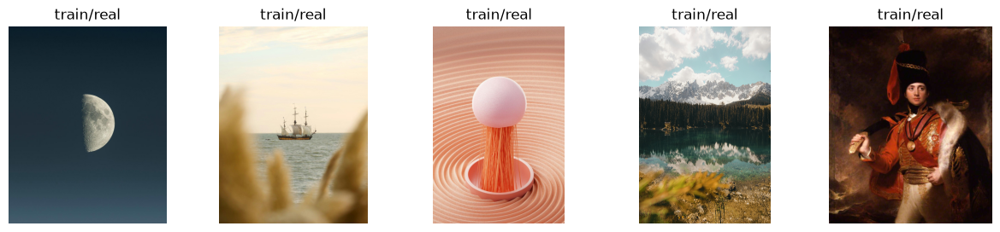

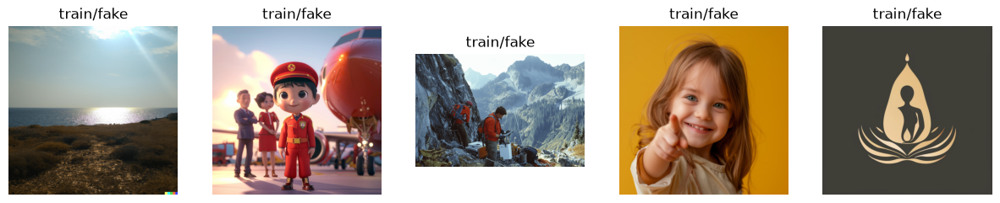

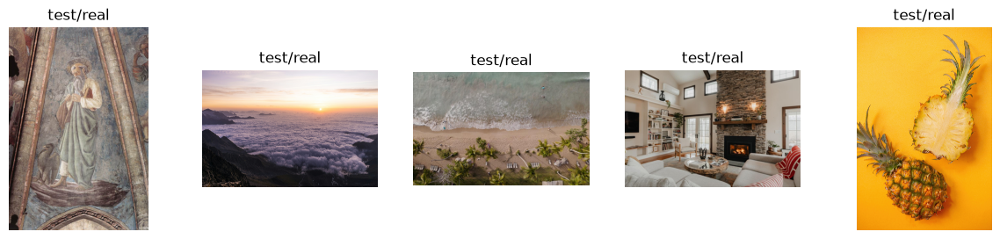

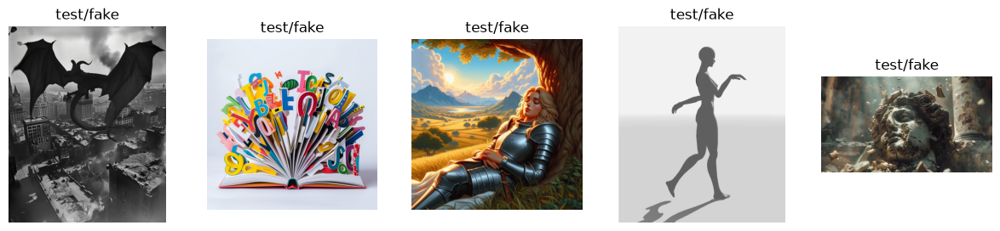

In [15]:
# Display example images
for split in ['train', 'test']:
    for category in ['real', 'fake']:
        helper_utils.show_random_images(split, category, path_dataset, num_images=5)

In [41]:
class AIvsRealDataset(Dataset):
    def __init__(self, root_dir, split='train', transform=None, return_folder=False):  # new arg
        self.root_dir = root_dir
        self.split = split
        self.transform = transform
        self.return_folder = return_folder  # new
        self.data = []

        for category in ['real', 'fake']:
            category_dir = os.path.join(root_dir, split, category)
            for img_name in os.listdir(category_dir):
                img_path = os.path.join(category_dir, img_name)
                self.data.append((img_path, category))

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        img_path, folder = self.data[idx]
        image = Image.open(img_path).convert('RGB')

        if self.transform:
            image = self.transform(image)

        if self.return_folder:  # new: EDA mode returns the folder name
            return image, folder

        label_tensor = torch.tensor(0 if folder == 'real' else 1)  # 0 for real, 1 for fake
        return image, label_tensor


In [42]:
#use MPS 
torch_device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {torch_device}")

Using device: mps


In [43]:
Image_dataset_train = AIvsRealDataset(root_dir=path_dataset, split='train', transform=None, return_folder=True)
Image_dataset_test = AIvsRealDataset(root_dir=path_dataset, split='test', transform=None)


In [53]:
def print_dataset_sizes(name, dataset):
    counts = Counter(folder for _, folder in dataset.data)
    print(f"{name} dataset size: {len(dataset)}")
    for folder in ("real", "fake"):
        print(f"  {folder}: {counts[folder]}")


print_dataset_sizes("Training", Image_dataset_train)
print_dataset_sizes("Test", Image_dataset_test)



Training dataset size: 48000
  real: 24000
  fake: 24000
Test dataset size: 12000
  real: 6000
  fake: 6000


Index: 6174
Folder: real
Image size (width, height): (1080, 720)



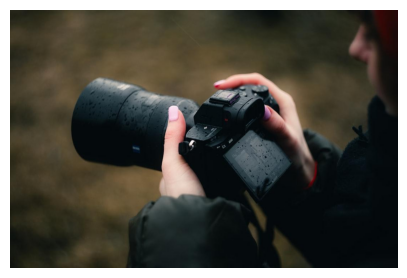

In [45]:
import random

sel_idx = random.randrange(len(Image_dataset_train))
img, folder = Image_dataset_train[sel_idx]

helper_utils.plot_img(img)

print(f"Index: {sel_idx}")
print(f"Folder: {folder}")
print(f"Image size (width, height): {img.size}\n")  # PIL image, since transform=None


In [ ]:
def visual_exploration(dataset, num_rows=2, num_cols=4):
    """Show random samples in a grid, titled with the folder each image came from."""
    total_samples = num_rows * num_cols
    indices = np.random.choice(len(dataset), total_samples, replace=False)

    fig, axes = helper_utils.get_grid(num_rows, num_cols, figsize=(num_cols * 3, num_rows * 4))

    for ax, idx in zip(axes.flatten(), indices):
        image, folder = dataset[idx]  # needs return_folder=True

        # PIL image has .size (width, height), a tensor has .shape (C, H, W)
        size = image.size if hasattr(image, "size") and not hasattr(image, "shape") else tuple(image.shape)

        info = f"Index: {idx} Size: {size}"
        helper_utils.plot_img(image, label=folder, info=info, ax=ax)

    plt.show()


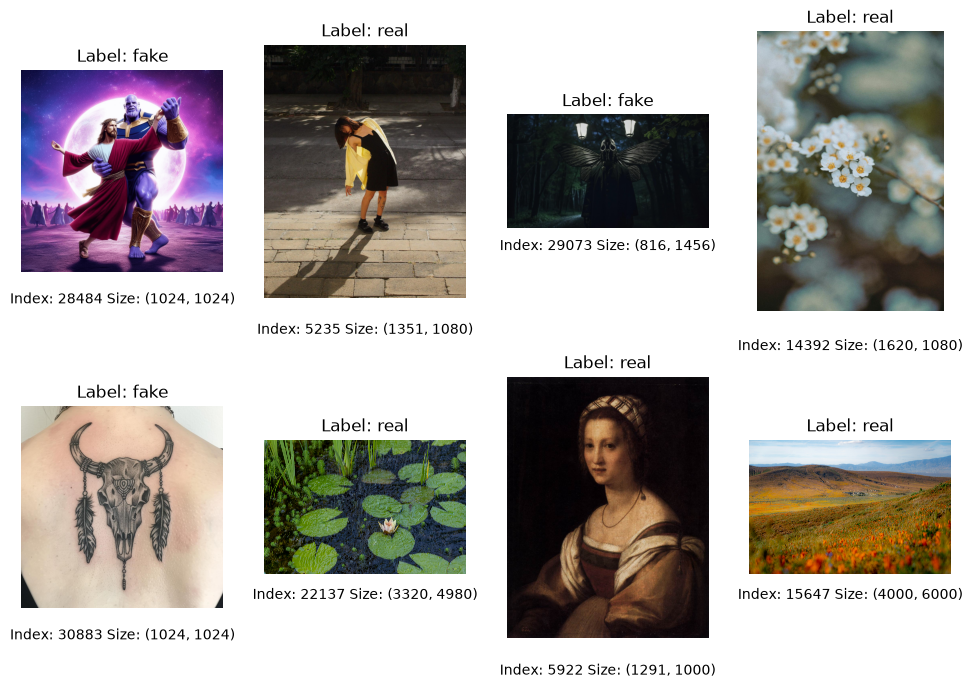

In [48]:
visual_exploration(Image_dataset_train, num_rows=2, num_cols=4)

In [49]:
helper_utils.dataset_images_per_class(path_dataset)

Total number of classes: 2

Number of images per class:

test                     : 0
train                    : 0


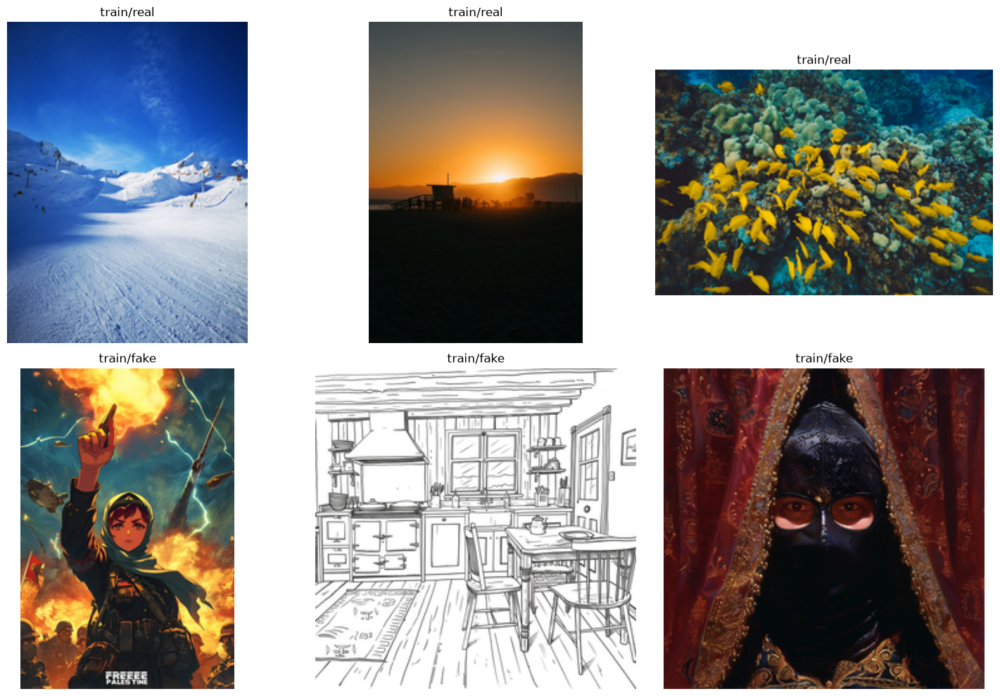

In [50]:
helper_utils.display_train_images(path_dataset)

In [57]:
import hashlib
import random
from collections import defaultdict
from pathlib import Path

import pandas as pd
from PIL import Image

root = Path(path_dataset)
IMG_EXT = {".jpg", ".png"}


def list_images(folder: Path) -> list[Path]:
    # suffix check is case-insensitive, so .JPG and .PNG are not missed
    return sorted(p for p in folder.iterdir() if p.suffix.lower() in IMG_EXT)


def sample_image_table(root: Path, per_group: int, seed: int = 42) -> pd.DataFrame:
    rng = random.Random(seed)
    rows = []
    for split in ("train", "test"):
        for label in ("fake", "real"):
            files = list_images(root / split / label)
            for ext in (".jpg", ".png"):
                group = [p for p in files if p.suffix.lower() == ext]
                if not group:  # real/png is empty
                    continue
                for path in rng.sample(group, k=min(per_group, len(group))):
                    with Image.open(path) as img:  # lazy, reads the header only
                        width, height = img.size
                        jpeg_q = img.quantization[0][0] if img.format == "JPEG" else None
                    rows.append({
                        "split": split, "label": label, "name": path.name,
                        "ext": ext.strip("."), "width": width, "height": height,
                        "file_bytes": path.stat().st_size, "jpeg_q": jpeg_q,
                    })
    df = pd.DataFrame(rows)
    df["bytes_per_px"] = df["file_bytes"] / (df["width"] * df["height"])
    return df


df = sample_image_table(root,per_group=1000, seed=42)
print(df.shape)
df.groupby(["split", "label", "ext"]).size()


(6000, 9)


split  label  ext
test   fake   jpg    1000
              png    1000
       real   jpg    1000
train  fake   jpg    1000
              png    1000
       real   jpg    1000
dtype: int64

## Are image sizes the same across fake and real?

In [58]:
# Spread of width and height per group
display(df.groupby(["label", "ext"])[["width", "height"]].agg(["min", "median", "max"]))

# The 5 most common resolutions per class
display(df.groupby("label")[["width", "height"]].value_counts().groupby(level=0).head(5))


width               height               
            min  median   max    min  median    max
label ext                                          
fake  jpg   331  1024.0  6720    346  1024.0   6400
      png   256  1024.0  5376    256  1024.0  14742
real  jpg   282  1080.0  9504    249  1620.0   9000

label  width  height
fake   1024   1024      1870
       1456   816        300
       2048   2048       201
       896    1344        95
       1344   896         95
real   1080   1620       303
              720        139
              1350        55
       4000   6000        44
       6000   4000        37
Name: count, dtype: int64

## Do file size and JPEG quality differ by class?

In [59]:
display(df.groupby(["label", "ext"])["file_bytes"].describe())
display(df.groupby(["label", "ext"])["bytes_per_px"].describe())  # compression density

# JPEG quantization value (lower means higher quality), jpg only
jpg = df[df["ext"] == "jpg"]
display(pd.crosstab(jpg["label"], jpg["jpeg_q"]))


count          mean           std      min        25%       50%  \
label ext                                                                     
fake  jpg  2000.0  2.263204e+05  2.983327e+05  10097.0  113436.00  154877.5   
      png  2000.0  8.858475e+05  1.117773e+06   3563.0  443821.25  579243.5   
real  jpg  2000.0  1.253794e+06  1.983215e+06  11489.0  125417.25  265350.5   

                  75%         max  
label ext                          
fake  jpg   228349.50   6201266.0  
      png   803879.25  15673109.0  
real  jpg  1823838.00  17493466.0

count      mean       std       min       25%       50%       75%  \
label ext                                                                       
fake  jpg  2000.0  0.138209  0.060041  0.023023  0.096082  0.128575  0.170808   
      png  2000.0  0.606546  0.360039  0.007532  0.414284  0.508366  0.620244   
real  jpg  2000.0  0.194666  0.176277  0.007944  0.103546  0.154542  0.228615   

                max  
label ext            
fake  jpg  0.797472  
      png  2.399526  
real  jpg  1.867979

jpeg_q,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,...,16.0,17.0,18.0,20.0,23.0,24.0,26.0,27.0,30.0,47.0
label,,,,,,,,,,,,,,,,,,,,,
fake,0,5,1,2,343,2,0,1647,0,0,...,0,0,0,0,0,0,0,0,0,0
real,69,44,32,699,24,59,9,956,3,12,...,8,1,2,3,3,2,3,6,1,2


## Are filenames reused across classes and splits? 

In [60]:
names = pd.DataFrame(
    [{"split": p.parent.parent.name, "label": p.parent.name, "name": p.name}
     for p in root.rglob("*") if p.is_file() and p.suffix.lower() in IMG_EXT]
)
print(f"Total files: {len(names)}")
print(f"Filenames appearing more than once: {names['name'].duplicated(keep=False).sum()}")
print(f"Distinct names used in both real and fake: "
      f"{(names.groupby('name')['label'].nunique() > 1).sum()}")


Total files: 60000
Filenames appearing more than once: 44775
Distinct names used in both real and fake: 15573


## Exact duplicates between train and test?

In [61]:
def file_md5(path: Path, chunk: int = 1 << 20) -> str:
    h = hashlib.md5()
    with open(path, "rb") as f:
        while block := f.read(chunk):
            h.update(block)
    return h.hexdigest()


all_files = [p for p in root.rglob("*") if p.is_file() and p.suffix.lower() in IMG_EXT]

# Files with a unique byte size cannot be duplicates, so only hash the rest
by_size = defaultdict(list)
for p in all_files:
    by_size[p.stat().st_size].append(p)
candidates = [p for group in by_size.values() if len(group) > 1 for p in group]
print(f"Hashing {len(candidates)} of {len(all_files)} files")

by_hash = defaultdict(list)
for p in candidates:
    by_hash[file_md5(p)].append(p)

dups = {h: ps for h, ps in by_hash.items() if len(ps) > 1}
cross_split = {h: ps for h, ps in dups.items() if len({p.parent.parent.name for p in ps}) > 1}
cross_label = {h: ps for h, ps in dups.items() if len({p.parent.name for p in ps}) > 1}

print(f"Exact duplicate groups: {len(dups)}")
print(f"Spanning train and test (leakage): {len(cross_split)}")
print(f"Spanning real and fake (label conflict): {len(cross_label)}")


Hashing 4613 of 60000 files
Exact duplicate groups: 41
Spanning train and test (leakage): 12
Spanning real and fake (label conflict): 0


In [62]:
for h, ps in cross_split.items():
    print([str(p.relative_to(root)) for p in ps])

# Test copies to drop (keep the train copy)
leak_files = sorted(
    str(p.relative_to(root))
    for ps in cross_split.values() for p in ps
    if p.parent.parent.name == "test"
)
print(len(leak_files))


['test/real/0264.jpg', 'train/real/12820.jpg']
['test/real/0629.jpg', 'train/real/15338.jpg']
['test/real/5463.jpg', 'train/real/19571.jpg']
['test/fake/2076.png', 'train/fake/22087.png']
['test/fake/1085.jpg', 'train/fake/18164.jpg']
['test/fake/2028.png', 'train/fake/22251.png']
['test/fake/1108.png', 'train/fake/18231.png']
['test/fake/0551.jpg', 'train/fake/12847.jpg']
['test/fake/0723.png', 'train/fake/16675.png']
['test/fake/0721.png', 'train/fake/16680.png']
['test/fake/1942.png', 'train/fake/21673.png']
['test/fake/1163.png', 'train/fake/18436.png']
12


In [63]:
%load_ext autoreload
%autoreload 2
from scan import scan_dataset

%time 
df_small = scan_dataset(path_dataset, "../data/interim/scan.csv", limit=500)
df_small["decode_ok"].value_counts()


CPU times: user 2 μs, sys: 0 ns, total: 2 μs
Wall time: 2.86 μs


decode_ok
True    500
Name: count, dtype: int64

In [64]:
df_scan = scan_dataset(path_dataset, "../data/interim/scan.csv")
print(df_scan.shape)

5000/60000 scanned
10000/60000 scanned
15000/60000 scanned
20000/60000 scanned
25000/60000 scanned
30000/60000 scanned
35000/60000 scanned
40000/60000 scanned
45000/60000 scanned
50000/60000 scanned
55000/60000 scanned
60000/60000 scanned
(60000, 17)


In [65]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image, ImageFile


def plot_rows(df: pd.DataFrame, root, n: int = 12, cols: int = 4, seed: int = 42) -> None:
    """Plot a random sample of scan rows in a grid, titled with label, name and error."""
    if df.empty:
        print("Nothing to plot")
        return
    root = Path(root)
    sample = df.sample(n=min(n, len(df)), random_state=seed)
    nrows = math.ceil(len(sample) / cols)
    fig, axes = plt.subplots(nrows, cols, figsize=(cols * 3.5, nrows * 3.5))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")

    ImageFile.LOAD_TRUNCATED_IMAGES = True  # show partial images instead of failing
    try:
        for ax, (_, r) in zip(axes, sample.iterrows()):
            err = "" if pd.isna(r["error"]) else str(r["error"])
            ax.set_title(f"{r['label']} | {Path(r['path']).name}\n{err[:50]}", fontsize=7)
            try:
                with Image.open(root / r["path"]) as img:
                    img.load()
                    thumb = img.convert("RGB")
                thumb.thumbnail((256, 256))
                ax.imshow(thumb)
            except Exception as e:
                ax.text(0.5, 0.5, f"cannot open\n{type(e).__name__}",
                        ha="center", va="center", fontsize=8)
    finally:
        ImageFile.LOAD_TRUNCATED_IMAGES = False  # always restore the strict default
    plt.tight_layout()
    plt.show()

In [66]:
def quick_eda(df: pd.DataFrame) -> None:
    print(f"Rows: {len(df)} | unique paths: {df['path'].nunique()}")

    print("\nColumns with missing values:")
    print(df.isna().sum()[lambda s: s > 0])

    print("\nSplit x label:")
    display(pd.crosstab(df["split"], df["label"]))

    print("\ndecode_ok:")
    print(df["decode_ok"].value_counts())
    failed = df[~df["decode_ok"]]
    if len(failed):
        print("\nTop errors:")
        print(failed["error"].astype(str).str[:80].value_counts().head(10))

    print("\nWarnings recorded:", int(df["warning"].notna().sum()))

    print("\nMode by label:")
    display(pd.crosstab(df["label"], df["mode"]))

    print("\nExtension vs actual format (a mismatch means a mislabeled file):")
    display(pd.crosstab(df["ext"], df["format"]))

    print("\nEXIF orientation by label (0 = no tag, 1 = normal, others need rotation):")
    display(pd.crosstab(df["label"], df["exif_orientation"].fillna(0).astype(int)))

    print("\nAspect ratio percentiles by label:")
    display(df.groupby("label")["aspect_ratio"].quantile([0.5, 0.9, 0.99, 1]).unstack())

    print("\nShort side percentiles by label:")
    short_side = df[["width", "height"]].min(axis=1)
    display(short_side.groupby(df["label"]).quantile([0, 0.01, 0.05, 0.5]).unstack())

    print("\nPixel std summary (near 0 means a blank image):")
    display(df.groupby("label")["pixel_std"].describe())
    print("Rows with pixel_std < 2:", int((df["pixel_std"] < 2).sum()))

    dup = df[df["md5"].notna() & df.duplicated("md5", keep=False)]
    groups = dup.groupby("md5").agg(n=("path", "size"), splits=("split", "nunique"),
                                    labels=("label", "nunique"))
    print(f"\nDuplicate groups: {len(groups)} | across train/test: {(groups['splits'] > 1).sum()}"
          f" | across real/fake: {(groups['labels'] > 1).sum()}")


quick_eda(df_scan)


Rows: 60000 | unique paths: 60000

Columns with missing values:
exif_orientation    58452
jpeg_q              10721
pixel_std              12
dtype: int64

Split x label:


label,fake,real
split,,
test,6000,6000
train,24000,24000



decode_ok:
decode_ok
True     59988
False       12
Name: count, dtype: int64

Top errors:
error
OSError: image file is truncated (6 bytes not processed)    3
OSError: broken data stream when reading image file         2
OSError: image file is truncated (0 bytes not processed)    2
OSError: image file is truncated (3 bytes not processed)    1
OSError: image file is truncated                            1
OSError: image file is truncated (2 bytes not processed)    1
OSError: image file is truncated (4 bytes not processed)    1
OSError: image file is truncated (1 bytes not processed)    1
Name: count, dtype: int64

Warnings recorded: 60000

Mode by label:


mode,CMYK,L,P,RGB,RGBA
label,,,,,
fake,0,1,9051,20786,162
real,4,41,3,29951,1



Extension vs actual format (a mismatch means a mislabeled file):


...


Short side percentiles by label:


,0.00,0.01,0.05,0.50
label,,,,
fake,224.0,512.0,555.0,1024.0
real,227.0,323.0,452.0,1080.0



Pixel std summary (near 0 means a blank image):


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
fake,29998.0,50.836899,13.843787,1.976450,41.321556,50.224985,59.384670,112.443365
real,29990.0,48.376211,17.739599,1.453306,36.106406,47.960953,60.261869,116.923404


Rows with pixel_std < 2: 4

Duplicate groups: 41 | across train/test: 12 | across real/fake: 0


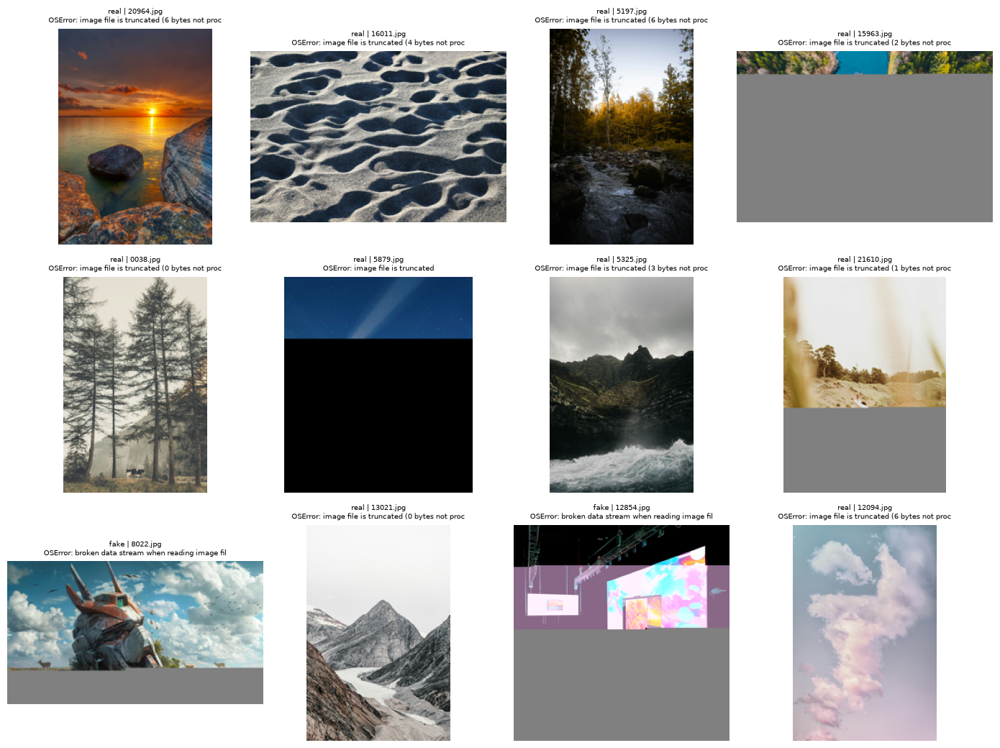

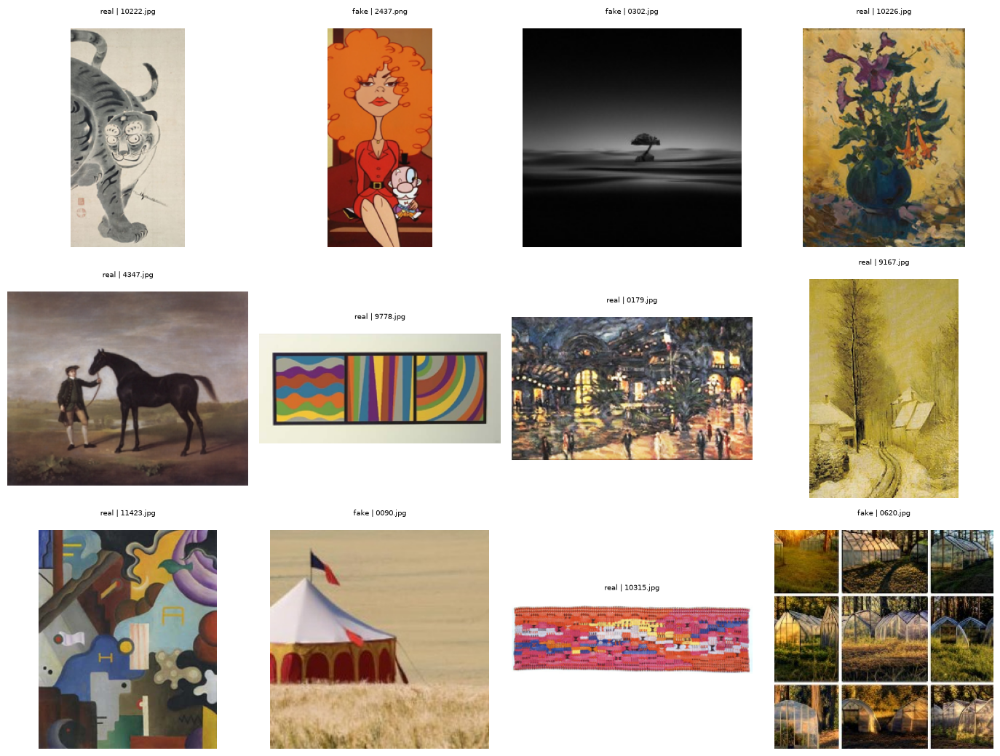

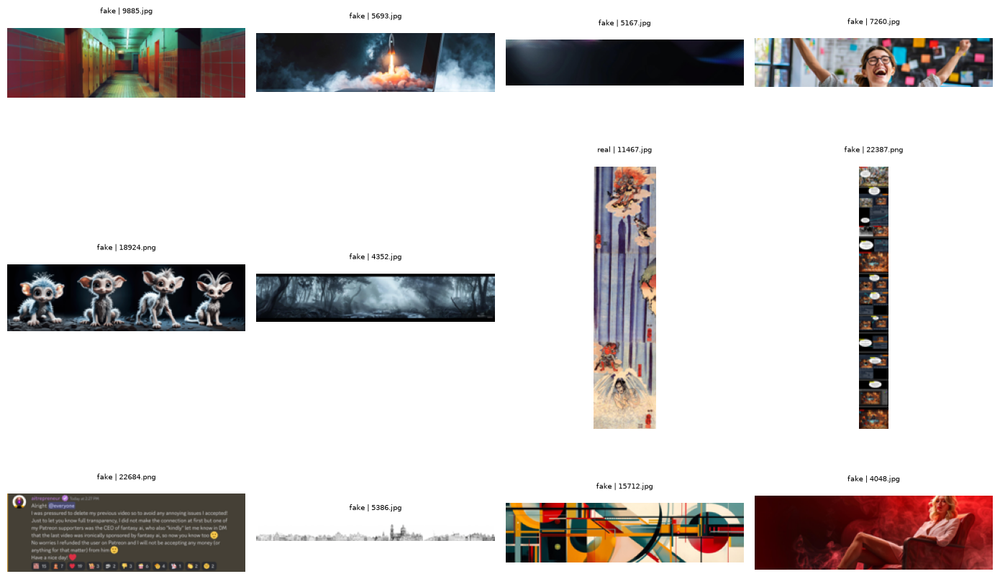

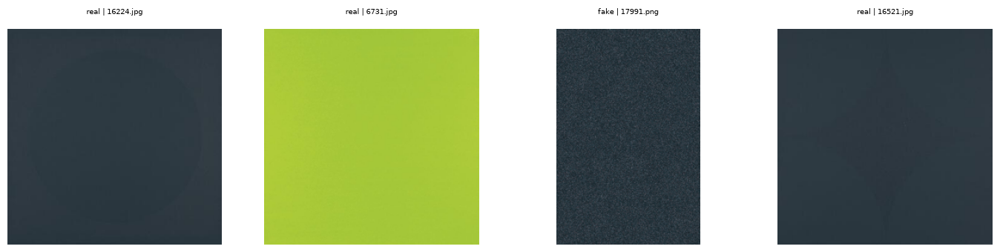

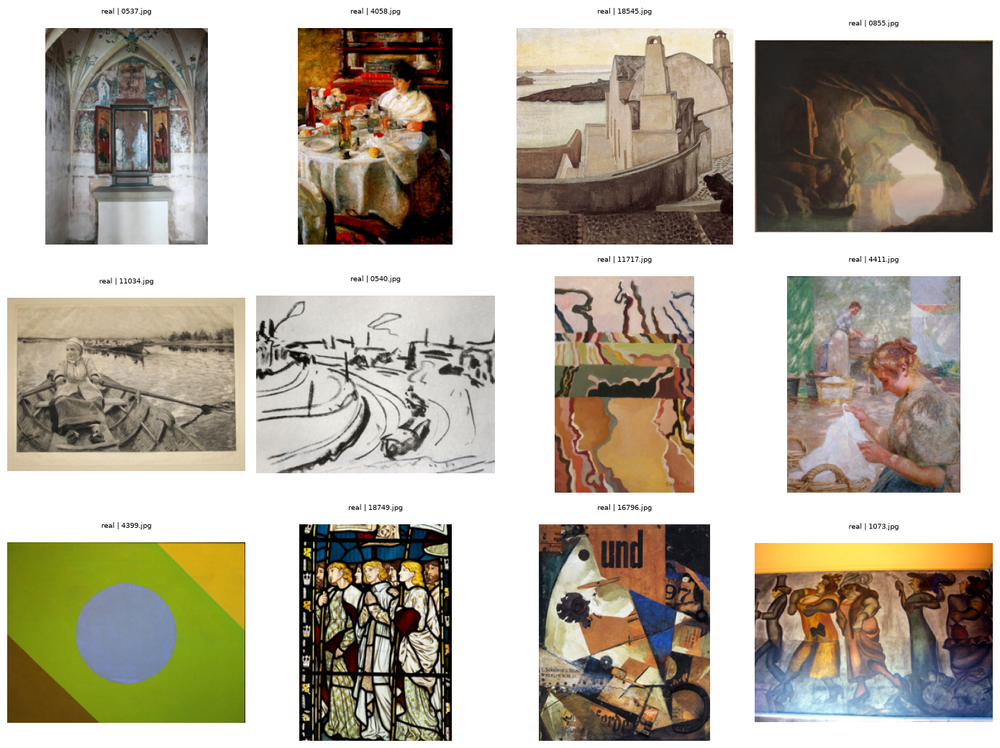

In [67]:
bad = df_scan[~df_scan["decode_ok"]]
plot_rows(bad, path_dataset)

# Other slices worth looking at
short = df_scan[["width", "height"]].min(axis=1)
plot_rows(df_scan[short < 256], path_dataset)                    # small images
plot_rows(df_scan[df_scan["aspect_ratio"] > 3], path_dataset)    # extreme shapes
plot_rows(df_scan[df_scan["pixel_std"] < 2], path_dataset)       # blank-ish
plot_rows(df_scan[df_scan["exif_orientation"].fillna(1) != 1], path_dataset)  # needs rotation


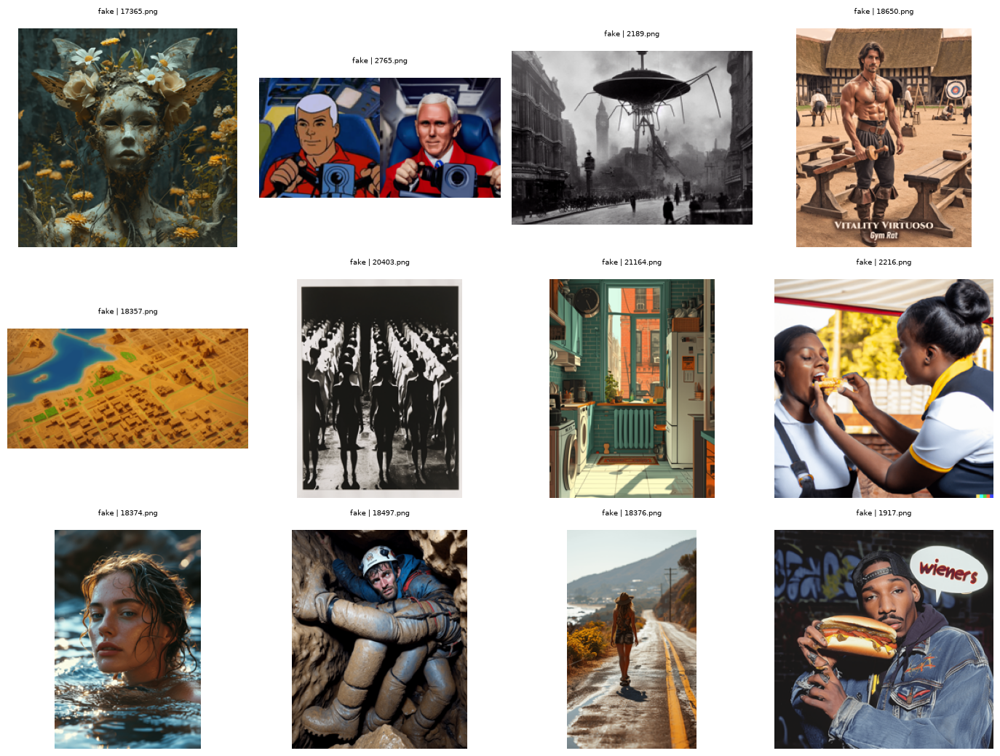

In [68]:
plot_rows(df_scan[df_scan["mode"] == "P"], path_dataset)

,short<256,aspect>3,aspect>4
label,,,
fake,13,112,34
real,28,31,6


label        fake   real
ext format              
jpg GIF         0      1
    JPEG    19310  29968
    MPO         0      1
    PNG         1     30
png PNG     10689      0

,path,label,width,height,pixel_std
21790,train/fake/17991.png,fake,512,768,1.976450
43846,train/real/16224.jpg,real,349,352,1.877783
44173,train/real/16521.jpg,real,349,351,1.453306
56731,train/real/6731.jpg,real,568,570,1.930921


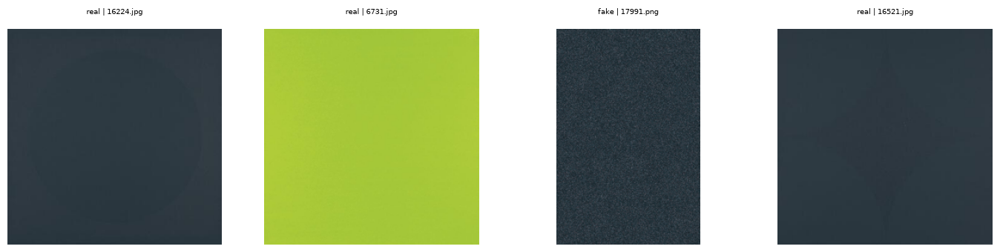

In [69]:
short = df_scan[["width", "height"]].min(axis=1)
display(pd.DataFrame({
    "short<256": (short < 256).groupby(df_scan["label"]).sum(),
    "aspect>3": (df_scan["aspect_ratio"] > 3).groupby(df_scan["label"]).sum(),
    "aspect>4": (df_scan["aspect_ratio"] > 4).groupby(df_scan["label"]).sum(),
}))
display(pd.crosstab([df_scan["ext"], df_scan["format"]], df_scan["label"]))

blank = df_scan[df_scan["pixel_std"] < 2]
display(blank[["path", "label", "width", "height", "pixel_std"]])
plot_rows(blank, path_dataset)


# EDA Summary: AI vs Real Image Classification

Source: full scan of all 60,000 images (`data/interim/scan.csv`). Items marked *proposed* are not final until confirmed.

## Dataset
| Split | fake | real |
|---|---|---|
| train | 24,000 | 24,000 |
| test | 6,000 | 6,000 |

Labels come from folder names. Classes are balanced. About 52GB raw.

## Shortcuts the model could learn (leaks)
| Leak | Evidence | Action |
|---|---|---|
| File format | Fakes: 10,690 PNG (36%), 19,310 JPEG. Reals: 29,968 JPEG, 30 PNG (named .jpg), 1 MPO, 1 GIF | Re-encode every image identically (lossless PNG). Use `format`, not `ext`, for slices |
| Resolution and shape | 47% of sampled fakes are 1024x1024, median aspect 1.0. Reals vary widely, median aspect 1.5 | Resize shorter side to 256, then center-crop, same method for all |
| JPEG quality | q=4: 699 real vs 2 fake. q=5: 343 fake vs 24 real. q=8: 1647 fake vs 956 real. A rule on q alone gets about 75% on JPEGs | Resize destroys most traces. Verify with a metadata-only baseline |
| Palette mode (P) | 9,051 fakes (30%) vs 3 reals. Only 256 colors after RGB conversion | Evaluate sliced by mode. Consider quantizing some real training images to 256 colors as augmentation |
| Minor modes | Grayscale: 41 real vs 1 fake. RGBA: 162 fake vs 1 real. CMYK: 4 real | Negligible, record in the manifest |
| EXIF | Tags on 1,531 reals, 0 fakes. 4 reals need rotation | Apply `exif_transpose`. PNG output drops the tags |
| Filenames | 44,775 of 60,000 names repeat. 15,573 names appear in both classes | Never use a filename as an ID. Use the relative path. Keep `split/label/` in the processed folder |

## Data health
- **Corrupt or truncated:** 12 files (0.02%).
- **Duplicates (exact, MD5):** 41 groups. 12 span train and test (leakage), 29 sit inside one split, 0 span real and fake.
- **Short side < 256:** 13 fake, 28 real. Minimum overall is 224.
- **Aspect ratio > 3:** 112 fake, 31 real. Above 4: 34 fake, 6 real.
- **Low contrast (pixel_std < 2):** 4 images, none near zero. To be viewed before deciding.
- **Extension vs content:** 31 `.jpg` files are really PNG, 1 GIF, 1 MPO.

## Proposed validate rules (config values)
| Rule | Value | Removes |
|---|---|---|
| decode succeeded | required | 12 |
| min short side | 256 | 41 |
| max aspect ratio | 3 | 143 |
| min pixel_std | 2 (or 1 if the 4 images look legitimate) | up to 4 |
| duplicates | drop test copies of train files, keep one per group | 12 plus within-split extras |
| normalize, do not drop | `exif_transpose`, convert to RGB, record mode | none |

Total removal is well under 1% of the data. The same rules should also apply to uploads at serving time.

## Preprocessing plan
1. Scan (this notebook), then validate (rules above), then split (seeded, no leaks), then resize (256, lossless PNG), then train.
2. Augmentation and normalization happen at training time only. Validation and test get resize and normalization only.
3. Train with random crop 224 from the 256 images. Eval and serve with center crop 224.
4. Compare input sizes (128, 224, 256) on a short run before settling.

## Evaluation plan
- Train a metadata-only baseline (format, `jpeg_q`, mode, original size). The CNN must beat it clearly.
- Report accuracy sliced by format, mode, and original resolution bucket.
- If possible, test on images from a generator not seen in training.

## Next
Phase 2: `configs/data.yaml`, manifest schema, and the package conversion.
